## Seminar 6: FastSpeech

**FastSpeech** — это неавторегрессионная модель для синтеза речи, которая генерирует мел-спектрограммы значительно быстрее, чем авторегрессионные модели и при этом сохраняет высокое качество речи.

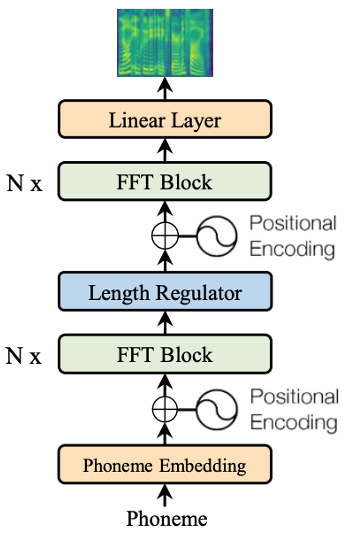

**Основные компоненты:**
1. **Feed-Forward Transformer** 
2. **Length Regulator**
3. **Duration Predictor**

В качестве вокодера мы будем использовать **HiFi-GAN**.

### Подготовка окружения

Рекомендуется Python 3.10 или 3.11. Выполните установку в ядро текущего ноутбука.

In [ ]:
%pip install "torch>=2.2,<3" "numpy>=1.26,<2" "matplotlib>=3.8,<4" "ipython>=8,<10" "gdown>=5.2,<6"

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import sys
import json
import re
from collections import OrderedDict
from IPython.display import Audio, display

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")

Device: cpu


<a name="hyperparameters"></a>
### Гиперпараметры

Параметры соответствуют используемому чекпойнту сторонней реализации FastSpeech. Это вариант архитектуры из статьи с дополнительным PostNet и посимвольным вводом.

Основные параметры модели:
*   `d_model`: размерность скрытых представлений (384)
*   `encoder_n_layer` / `decoder_n_layer`: количество слоев трансформера (6)
*   `n_src_vocab`: число строк таблицы эмбеддингов в предобученных весах (149); посимвольный ввод использует только часть из них

In [2]:
class HP:
    # Model
    n_src_vocab = 149  # Preserve the full embedding size expected by the checkpoint.
    max_sep_len = 2048
    word_vec_dim = 384
    d_model = 384
    
    # Encoder
    encoder_n_layer = 6
    encoder_head = 2
    encoder_conv1d_filter_size = 1536
    encoder_output_size = 384
    
    # Decoder
    decoder_n_layer = 6
    decoder_head = 2
    decoder_conv1d_filter_size = 1536
    decoder_output_size = 384
    
    # Duration Predictor
    duration_predictor_filter_size = 256
    duration_predictor_kernel_size = 3
    
    # FFT Block
    fft_conv1d_kernel = 3
    fft_conv1d_padding = 1
    
    # Mel
    num_mels = 80
    
    # Common
    dropout = 0.1
    
hp = HP()

<a name="text-processing"></a>
### Обработка текста

Используем **посимвольный ввод**: модель получает числовые идентификаторы английских букв, пробела и знаков пунктуации.

`text_to_sequence` переводит текст в нижний регистр, заменяет переносы строк и повторные пробелы одним пробелом и возвращает индексы символов. Числа нужно писать английскими словами.

In [3]:
# Keep the original character order to match the pretrained embedding indices.
_pad = '_'
_punctuation = '!\'(),.:;? '
_special = '-'
_letters = 'ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz'

symbols = [_pad] + list(_special) + list(_punctuation) + list(_letters)
PAD = symbols.index(_pad)

_symbol_to_id = {s: i for i, s in enumerate(symbols)}

def text_to_sequence(text: str) -> list:
    """Encode supported English characters without silently discarding content."""
    text = re.sub(r"\s+", " ", text.lower()).strip()
    allowed = set(_letters.lower() + _punctuation + _special)
    unsupported = sorted(set(text) - allowed)
    if unsupported:
        raise ValueError(
            f"Unsupported characters: {unsupported}. "
            "Use English letters and punctuation; spell out numbers."
        )
    return [_symbol_to_id[c] for c in text]

print(f"Vocabulary size (including PAD): {len(symbols)}")
print(f"Test sequence: {text_to_sequence('Hello!')}")

Vocabulary size (including PAD): 64
Test sequence: [45, 42, 49, 49, 52, 2]


<a name="utils"></a>
### Вспомогательные функции

Здесь определены функции для создания масок и позиционного кодирования.

In [5]:
def get_sinusoid_encoding_table(n_position, d_hid, padding_idx=None):
    """Build fixed sinusoidal position embeddings, optionally zeroing the padding row."""
    def cal_angle(position, hid_idx):
        return position / np.power(10000, 2 * (hid_idx // 2) / d_hid)
    
    def get_posi_angle_vec(position):
        return [cal_angle(position, hid_j) for hid_j in range(d_hid)]
    
    sinusoid_table = np.array([get_posi_angle_vec(pos_i) for pos_i in range(n_position)])
    sinusoid_table[:, 0::2] = np.sin(sinusoid_table[:, 0::2])
    sinusoid_table[:, 1::2] = np.cos(sinusoid_table[:, 1::2])
    
    if padding_idx is not None:
        sinusoid_table[padding_idx] = 0.
    
    return torch.FloatTensor(sinusoid_table)

def get_non_pad_mask(seq):
    """Return a [batch, length, 1] mask that keeps non-padding positions."""
    return seq.ne(PAD).type(torch.float).unsqueeze(-1)

def get_attn_key_pad_mask(seq_k, seq_q):
    """Mask padded keys for every query position in self-attention."""
    len_q = seq_q.size(1)
    padding_mask = seq_k.eq(PAD)
    padding_mask = padding_mask.unsqueeze(1).expand(-1, len_q, -1)
    return padding_mask

def pad_list(inputs, mel_max_length=None):
    """Pad variable-length [time, channels] tensors and stack them into a batch."""
    if mel_max_length:
        max_len = mel_max_length
    else:
        max_len = max([inputs[i].size(0) for i in range(len(inputs))])
    
    out_list = []
    for batch in inputs:
        one_batch_padded = F.pad(batch, (0, 0, 0, max_len - batch.size(0)), "constant", 0.0)
        out_list.append(one_batch_padded)
    
    return torch.stack(out_list)

<a name="transformer-components"></a>
### Компоненты Трансформера

Основные блоки архитектуры:
1.  **Scaled Dot-Product Attention**
2.  **Multi-Head Attention**
3.  **Position-wise Feed-Forward**

In [6]:
class ScaledDotProductAttention(nn.Module):
    def __init__(self, temperature, attn_dropout=0.1):
        super().__init__()
        self.temperature = temperature
        self.dropout = nn.Dropout(attn_dropout)
        self.softmax = nn.Softmax(dim=2)

    def forward(self, q, k, v, mask=None):
        """Compute scaled attention over unmasked keys and aggregate their values."""
        attn = torch.bmm(q, k.transpose(1, 2))
        attn = attn / self.temperature

        if mask is not None:
            attn = attn.masked_fill(mask, -np.inf)

        attn = self.softmax(attn)
        attn = self.dropout(attn)
        output = torch.bmm(attn, v)

        return output, attn

class MultiHeadAttention(nn.Module):
    def __init__(self, n_head, d_model, d_k, d_v, dropout=0.1):
        super().__init__()

        self.n_head = n_head
        self.d_k = d_k
        self.d_v = d_v

        self.w_qs = nn.Linear(d_model, n_head * d_k)
        self.w_ks = nn.Linear(d_model, n_head * d_k)
        self.w_vs = nn.Linear(d_model, n_head * d_v)

        self.attention = ScaledDotProductAttention(temperature=np.power(d_k, 0.5))
        self.layer_norm = nn.LayerNorm(d_model)

        self.fc = nn.Linear(n_head * d_v, d_model)

        self.dropout = nn.Dropout(dropout)

    def forward(self, q, k, v, mask=None):
        """Apply parallel attention heads, merge their outputs, and add the residual."""
        d_k, d_v, n_head = self.d_k, self.d_v, self.n_head

        sz_b, len_q, _ = q.size()
        sz_b, len_k, _ = k.size()
        sz_b, len_v, _ = v.size()

        residual = q

        q = self.w_qs(q).view(sz_b, len_q, n_head, d_k)
        k = self.w_ks(k).view(sz_b, len_k, n_head, d_k)
        v = self.w_vs(v).view(sz_b, len_v, n_head, d_v)

        # Fold heads into the batch dimension for batched attention.
        q = q.permute(2, 0, 1, 3).contiguous().view(-1, len_q, d_k)
        k = k.permute(2, 0, 1, 3).contiguous().view(-1, len_k, d_k)
        v = v.permute(2, 0, 1, 3).contiguous().view(-1, len_v, d_v)

        if mask is not None:
            mask = mask.repeat(n_head, 1, 1)

        output, attn = self.attention(q, k, v, mask=mask)

        output = output.view(n_head, sz_b, len_q, d_v)
        output = output.permute(1, 2, 0, 3).contiguous().view(sz_b, len_q, -1)

        output = self.dropout(self.fc(output))
        output = self.layer_norm(output + residual)

        return output, attn

class PositionwiseFeedForward(nn.Module):
    def __init__(self, d_in, d_hid, kernel_size, dropout=0.1):
        super().__init__()
        
        self.w_1 = nn.Conv1d(
            d_in, d_hid, kernel_size=kernel_size[0], padding=(kernel_size[0] - 1) // 2)
        self.w_2 = nn.Conv1d(
            d_hid, d_in, kernel_size=kernel_size[1], padding=(kernel_size[1] - 1) // 2)
        
        self.layer_norm = nn.LayerNorm(d_in)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        residual = x
        output = x.transpose(1, 2)
        output = self.w_2(F.relu(self.w_1(output)))
        output = output.transpose(1, 2)
        output = self.dropout(output)
        output = self.layer_norm(output + residual)
        
        return output

<a name="fft-block"></a>
### FFT Block

**Feed-Forward Transformer (FFT) Block** — это единичный слой энкодера и декодера.
Он состоит из **Multi-Head Attention** и **Conv1D** (Position-wise Feed-Forward) слоёв. 

В FastSpeech энкодер и декодер состоят из стопки таких блоков (по 6 штук).

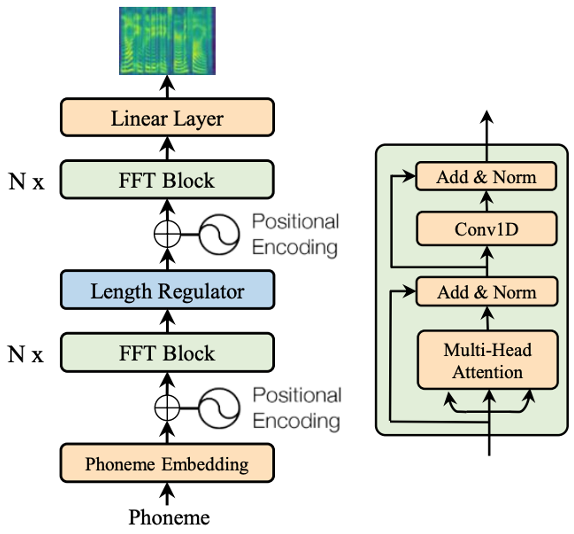

In [7]:
class FFTBlock(nn.Module):
    def __init__(self, d_model, d_inner, n_head, d_k, d_v, dropout=0.1):
        super().__init__()
        self.slf_attn = MultiHeadAttention(n_head, d_model, d_k, d_v, dropout=dropout)
        self.pos_ffn = PositionwiseFeedForward(
            d_model, d_inner, kernel_size=[hp.fft_conv1d_kernel, hp.fft_conv1d_kernel], dropout=dropout)

    def forward(self, enc_input, non_pad_mask=None, slf_attn_mask=None):
        """Combine self-attention and temporal convolutions while zeroing padded positions."""
        enc_output, enc_slf_attn = self.slf_attn(
            enc_input, enc_input, enc_input, mask=slf_attn_mask)
        
        if non_pad_mask is not None:
            enc_output = enc_output * non_pad_mask

        enc_output = self.pos_ffn(enc_output)
        
        if non_pad_mask is not None:
            enc_output = enc_output * non_pad_mask

        return enc_output, enc_slf_attn

<a name="base-layers"></a>
### Conv и Linear слои

Здесь мы определяем базовые сверточные и линейные слои с правильной инициализацией весов.

*   `Conv`: Используется в `DurationPredictor`.
*   `ConvNorm`: Обычная свертка без транспонирования, используется в `PostNet`.

In [8]:
class Conv(nn.Module):
    """Conv with internal transpose for DurationPredictor"""
    def __init__(self, in_channels, out_channels, kernel_size=1, stride=1,
                 padding=0, dilation=1, bias=True, w_init='linear'):
        super().__init__()
        
        self.conv = nn.Conv1d(in_channels, out_channels,
                              kernel_size=kernel_size, stride=stride,
                              padding=padding, dilation=dilation, bias=bias)
        nn.init.xavier_uniform_(self.conv.weight, gain=nn.init.calculate_gain(w_init))

    def forward(self, x):
        # Transpose input: [batch, seq, channels] -> [batch, channels, seq]
        x = x.contiguous().transpose(1, 2)
        x = self.conv(x)
        x = x.contiguous().transpose(1, 2)
        return x

class ConvNorm(nn.Module):
    """ConvNorm without transpose for PostNet"""
    def __init__(self, in_channels, out_channels, kernel_size=1, stride=1,
                 padding=0, dilation=1, bias=True, w_init='linear'):
        super().__init__()
        
        self.conv = nn.Conv1d(in_channels, out_channels,
                              kernel_size=kernel_size, stride=stride,
                              padding=padding, dilation=dilation, bias=bias)
        nn.init.xavier_uniform_(self.conv.weight, gain=nn.init.calculate_gain(w_init))

    def forward(self, x):
        # Uses standard layout: [batch, channels, seq]
        return self.conv(x)

class Linear(nn.Module):
    def __init__(self, in_dim, out_dim, bias=True, w_init='linear'):
        super().__init__()
        self.linear_layer = nn.Linear(in_dim, out_dim, bias=bias)
        nn.init.xavier_uniform_(self.linear_layer.weight,
                                gain=nn.init.calculate_gain(w_init))

    def forward(self, x):
        return self.linear_layer(x)

<a name="post-net"></a>
### Post-Net

**Post-Net** — это модуль постобработки, который улучшает качество сгенерированной мел-спектрограммы.
Он состоит из 5 слоев одномерных сверток. 

На вход подается спектрограмма, предсказанная декодером, а PostNet предсказывает "остаток", который добавляется к исходному предсказанию.

Это дополнительный модуль, его нет в схеме оригинального FastSpeech.

In [9]:
class PostNet(nn.Module):
    def __init__(self, n_mel_channels=80, postnet_embedding_dim=512,
                 postnet_kernel_size=5, postnet_n_convolutions=5):
        super().__init__()
        self.convolutions = nn.ModuleList()

        self.convolutions.append(
            nn.Sequential(
                ConvNorm(n_mel_channels, postnet_embedding_dim,
                         kernel_size=postnet_kernel_size, stride=1,
                         padding=int((postnet_kernel_size - 1) / 2),
                         dilation=1, w_init='tanh'),
                nn.BatchNorm1d(postnet_embedding_dim))
        )

        for i in range(1, postnet_n_convolutions - 1):
            self.convolutions.append(
                nn.Sequential(
                    ConvNorm(postnet_embedding_dim,
                             postnet_embedding_dim,
                             kernel_size=postnet_kernel_size, stride=1,
                             padding=int((postnet_kernel_size - 1) / 2),
                             dilation=1, w_init='tanh'),
                    nn.BatchNorm1d(postnet_embedding_dim))
            )

        self.convolutions.append(
            nn.Sequential(
                ConvNorm(postnet_embedding_dim, n_mel_channels,
                         kernel_size=postnet_kernel_size, stride=1,
                         padding=int((postnet_kernel_size - 1) / 2),
                         dilation=1, w_init='linear'),
                nn.BatchNorm1d(n_mel_channels))
        )

    def forward(self, x):
        # [batch, seq, channels] -> [batch, channels, seq]
        """Predict a residual correction for a [batch, frames, mel_channels] spectrogram."""
        x = x.contiguous().transpose(1, 2)
        
        for i in range(len(self.convolutions) - 1):
            x = torch.tanh(self.convolutions[i](x))
        
        x = self.convolutions[-1](x)
        
        # Back to [batch, seq, channels]
        x = x.contiguous().transpose(1, 2)
        return x

<a name="duration-predictor"></a>
### Duration Predictor

**Duration Predictor** берёт скрытые представления из энкодера и предсказывает число кадров мел-спектрограммы для каждого входного токена (здесь — символа).

В этой реализации выход интерпретируется как неотрицательная длительность в кадрах. В [оригинальной статье](https://proceedings.neurips.cc/paper/2019/file/f63f65b503e22cb970527f23c9ad7db1-Paper.pdf) длительности предсказываются в логарифмическом пространстве. Мы сохраняем интерпретацию, совместимую с используемыми весами.

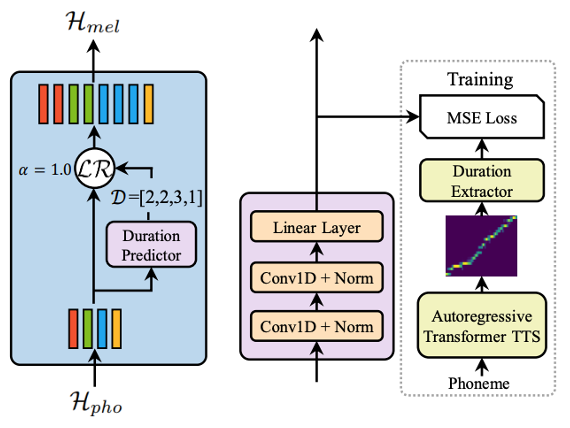

In [15]:
class DurationPredictor(nn.Module):
    def __init__(self):
        super().__init__()

        self.input_size = hp.d_model
        self.filter_size = hp.duration_predictor_filter_size
        self.kernel = hp.duration_predictor_kernel_size
        self.conv_output_size = hp.duration_predictor_filter_size
        self.dropout = hp.dropout

        self.conv_layer = nn.Sequential(OrderedDict([
            ("conv1d_1", Conv(self.input_size, self.filter_size,
                              kernel_size=self.kernel, padding=1)),
            ("layer_norm_1", nn.LayerNorm(self.filter_size)),
            ("relu_1", nn.ReLU()),
            ("dropout_1", nn.Dropout(self.dropout)),
            ("conv1d_2", Conv(self.filter_size, self.filter_size,
                              kernel_size=self.kernel, padding=1)),
            ("layer_norm_2", nn.LayerNorm(self.filter_size)),
            ("relu_2", nn.ReLU()),
            ("dropout_2", nn.Dropout(self.dropout))
        ]))

        self.linear_layer = Linear(self.conv_output_size, 1)
        self.relu = nn.ReLU()

    def forward(self, encoder_output):
        """Predict nonnegative frame durations for each input character."""
        out = self.conv_layer(encoder_output)
        out = self.linear_layer(out)
        out = self.relu(out)
        return out.squeeze(-1)  # Always [batch, text_length], including length 1.

<a name="length-regulator"></a>
### Length Regulator

**Length Regulator** выполняет операцию растягивания последовательности токенов в соответствии с предсказанными длительностями.

Если символу 'a' соответствует длительность 3 кадра, его вектор повторяется 3 раза.
Параметр $\alpha$ позволяет управлять скоростью речи: умножая длительности на число, мы можем ускорять или замедлять речь: $\alpha < 1$ ускоряет, $\alpha > 1$ замедляет. После умножения длительности округляются до целых кадров.

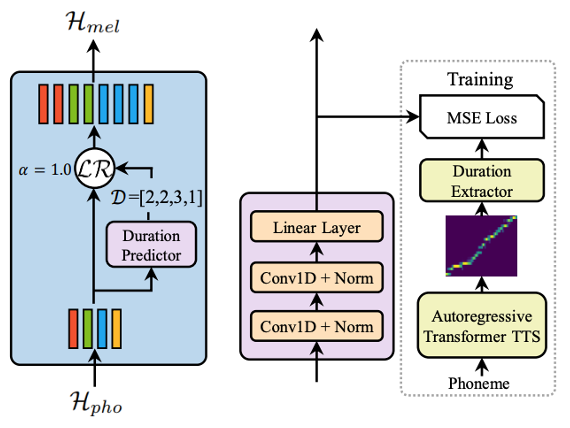

In [16]:
class LengthRegulator(nn.Module):
    def __init__(self):
        super().__init__()
        self.duration_predictor = DurationPredictor()

    def LR(self, x, durations, alpha=1.0, mel_max_length=None):
        """Repeat character states by scaled, rounded durations and return frame positions."""
        durations = torch.as_tensor(durations, device=x.device, dtype=x.dtype)
        # Scale first, then round half up, as in the examples in the paper.
        scaled = durations * alpha
        repeats = torch.floor(scaled + 0.5).long()
        lengths = repeats.sum(dim=1)
        max_length = int(lengths.max().item())
        if mel_max_length is not None:
            max_length = mel_max_length
        # Convert character-level states to frame-level states before decoding.
        expanded = [torch.repeat_interleave(row, count, dim=0)
                    for row, count in zip(x, repeats)]
        output = pad_list(expanded, max_length)
        # Position zero is reserved for padded frames.
        positions = torch.arange(1, max_length + 1, device=x.device).unsqueeze(0)
        positions = positions.expand(x.size(0), -1).masked_fill(
            positions > lengths.unsqueeze(1), 0)
        return output, positions

    def forward(self, x, alpha=1.0, target=None, mel_max_length=None, non_pad_mask=None):
        """Expand states using target durations during training or predictions during inference."""
        predicted = self.duration_predictor(x)
        valid = (non_pad_mask.squeeze(-1).bool() if non_pad_mask is not None
                 else torch.ones_like(predicted, dtype=torch.bool))
        predicted = predicted.masked_fill(~valid, 0.0)
        if self.training:
            durations = torch.as_tensor(target, device=x.device)
            output, _ = self.LR(x, durations.masked_fill(~valid, 0),
                                mel_max_length=mel_max_length)
            return output, predicted
        return self.LR(x, predicted, alpha=alpha)

<a name="encoder-decoder"></a>
### Энкодер и Декодер

Модули энкодера и декодера состоят из стека FFT-блоков:
*   **Энкодер** преобразует последовательность символов в скрытые представления.
*   **Декодер** преобразует растянутую последовательность после Length Regulator в мел-спектрограмму.

In [17]:
class Encoder(nn.Module):
    def __init__(self):
        super().__init__()
        
        n_src_vocab = hp.n_src_vocab
        len_max_seq = hp.max_sep_len
        n_position = len_max_seq + 1
        d_word_vec = hp.word_vec_dim
        n_layers = hp.encoder_n_layer
        n_head = hp.encoder_head
        d_k = 64
        d_v = 64
        d_model = hp.d_model
        d_inner = hp.encoder_conv1d_filter_size
        dropout = hp.dropout

        self.src_word_emb = nn.Embedding(n_src_vocab, d_word_vec, padding_idx=PAD)
        self.position_enc = nn.Embedding.from_pretrained(
            get_sinusoid_encoding_table(n_position, d_word_vec, padding_idx=0), freeze=True)
        
        self.layer_stack = nn.ModuleList([
            FFTBlock(d_model, d_inner, n_head, d_k, d_v, dropout=dropout)
            for _ in range(n_layers)])

    def forward(self, src_seq, src_pos):
        
        """Encode character IDs and positions into contextual states and a padding mask."""
        # Mask PAD keys only; attention is bidirectional (no causal mask).
        slf_attn_mask = get_attn_key_pad_mask(seq_k=src_seq, seq_q=src_seq)
        # Zero out hidden states at padded positions.
        non_pad_mask = get_non_pad_mask(src_seq)
        
        enc_output = self.src_word_emb(src_seq) + self.position_enc(src_pos)

        for enc_layer in self.layer_stack:
            enc_output, _ = enc_layer(
                enc_output, non_pad_mask=non_pad_mask, slf_attn_mask=slf_attn_mask)

        return enc_output, non_pad_mask

class Decoder(nn.Module):
    def __init__(self):
        super().__init__()
        
        len_max_seq = hp.max_sep_len
        n_position = len_max_seq + 1
        d_word_vec = hp.word_vec_dim
        n_layers = hp.decoder_n_layer
        n_head = hp.decoder_head
        d_k = 64
        d_v = 64
        d_model = hp.d_model
        d_inner = hp.decoder_conv1d_filter_size
        dropout = hp.dropout

        self.position_enc = nn.Embedding.from_pretrained(
            get_sinusoid_encoding_table(n_position, d_word_vec, padding_idx=0), freeze=True)
        
        self.layer_stack = nn.ModuleList([
            FFTBlock(d_model, d_inner, n_head, d_k, d_v, dropout=dropout)
            for _ in range(n_layers)])

    def forward(self, enc_seq, enc_pos):
        
        """Transform duration-expanded states into frame-level features with FFT blocks."""
        # Mask PAD keys only; attention is bidirectional (no causal mask).
        slf_attn_mask = get_attn_key_pad_mask(seq_k=enc_pos, seq_q=enc_pos)
        # Zero out hidden states at padded positions.
        non_pad_mask = get_non_pad_mask(enc_pos)
        
        dec_output = enc_seq + self.position_enc(enc_pos)

        for dec_layer in self.layer_stack:
            dec_output, _ = dec_layer(
                dec_output, non_pad_mask=non_pad_mask, slf_attn_mask=slf_attn_mask)

        return dec_output

<a name="fastspeech-model"></a>
### FastSpeech

Собираем все компоненты вместе в единый класс `FastSpeech`.

1. `Encoder` кодирует текст.
2. `Duration Predictor` предсказывает длительности символов, а `Length Regulator` повторяет их представления согласно этим длительностям.
3. `Decoder` генерирует черновую мел-спектрограмму.
4. `PostNet` улучшает результат.

In [18]:
class FastSpeech(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder = Encoder()
        self.length_regulator = LengthRegulator()
        self.decoder = Decoder()

        self.mel_linear = Linear(hp.decoder_output_size, hp.num_mels)
        self.postnet = PostNet()

    def forward(self, src_seq, src_pos, mel_pos=None, mel_max_length=None,
                length_target=None, alpha=1.0):
        """Generate initial and refined mel-spectrograms; return duration predictions in training."""
        encoder_output, non_pad_mask = self.encoder(src_seq, src_pos)

        # Expand character states to frames using target or predicted durations.
        if self.training:
            expanded, duration_predictions = self.length_regulator(
                encoder_output, target=length_target,
                mel_max_length=mel_max_length, non_pad_mask=non_pad_mask)
            decoder_pos = mel_pos
        else:
            expanded, decoder_pos = self.length_regulator(
                encoder_output, alpha=alpha, non_pad_mask=non_pad_mask)

        decoder_output = self.decoder(expanded, decoder_pos)

        # Project frame features to mel bins and add the PostNet correction.
        mel_output = self.mel_linear(decoder_output)
        mel_output_postnet = mel_output + self.postnet(mel_output)

        if self.training:
            return mel_output, mel_output_postnet, duration_predictions
        return mel_output, mel_output_postnet


<a name="load-weights"></a>
### Загрузка предобученных весов

Загрузим предобученные FastSpeech и HiFi-GAN для синтеза речи.

Исходные реализации: [FastSpeech](https://github.com/sanjosh/FastSpeech-1), [HiFi-GAN](https://github.com/jik876/hifi-gan).


In [19]:
from pathlib import Path
import hashlib
import urllib.request
import shutil
import gdown

# Run the notebook from the seminar directory to resolve asset paths.
ASSET_DIR = Path("sem6_assets").resolve()
ASSET_DIR.mkdir(parents=True, exist_ok=True)
FASTSPEECH_URL = "https://drive.google.com/file/d/1v-vHbYbxkepgu7n3ZLotOPp40j4eJEDW/view?usp=drive_link"
HIFIGAN_COMMIT = "4769534d45265d52a904b850da5a622601885777"


def sha256(path):
    """Compute a file checksum in chunks without loading the whole file into memory."""
    digest = hashlib.sha256()
    with Path(path).open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def ensure_file(path, expected_sha256, url=None, drive_id=None):
    """Reuse or download an asset and verify its SHA-256 checksum before returning its path."""
    path = Path(path)
    if path.is_file():
        if sha256(path) != expected_sha256:
            raise RuntimeError(f"Checksum mismatch: {path}. Remove the corrupted file and download it again.")
        print(f"Verified: {path.name}")
        return path
    if not url and not drive_id:
        raise FileNotFoundError(
            f"Missing {path}. Provide the asset file "
            "or supply a public download URL."
        )
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".part")
    try:
        print(f"Downloading: {path.name}")
        if drive_id:
            result = gdown.download(id=drive_id, output=str(temporary), quiet=False)
            if result is None:
                raise RuntimeError("Google Drive did not return a file")
        elif "drive.google.com/" in url:
            result = gdown.download(url=url, output=str(temporary), fuzzy=True, quiet=False)
            if result is None:
                raise RuntimeError("Google Drive did not return a file")
        else:
            with urllib.request.urlopen(url, timeout=120) as response, temporary.open("wb") as f:
                shutil.copyfileobj(response, f)
        if sha256(temporary) != expected_sha256:
            raise RuntimeError(f"Checksum mismatch for {path.name}: the URL must serve the original file, not an HTML page.")
        temporary.replace(path)
    finally:
        temporary.unlink(missing_ok=True)
    return path

checkpoint_path = ensure_file(
    ASSET_DIR / "checkpoint_112000.pth.tar",
    "87c69f01a4e9863a065ecc5294942bbd4bc6ece1f570e642a080054f88566890",
    url=FASTSPEECH_URL or None,
)
hifigan_checkpoint_path = ensure_file(
    ASSET_DIR / "generator_universal.pth",
    "771eaf4876485a35e25577563d390c262e23c2421e4a8c929eacfde34a5b7a60",
    drive_id="1qpgI41wNXFcH-iKq1Y42JlBC9j0je8PW",
)
hifigan_config_path = ensure_file(
    ASSET_DIR / "hifigan_config.json", "c1bd98e99062ddbced38729a5252dc2aa772328d16d70097ac139dab2f269dc9",
    drive_id="1pAB2kQunkDuv6W5fcJiQ0CY8xcJKB22e",
)
hifigan_dir = ASSET_DIR / "hifi-gan"
for filename, digest in {'env.py': 'f5212e8402468ba2b68f79fac906ae48b0762625db368232bbff3bc31fa2b42b', 'models.py': '6b2c446e551fa3f0855cf02d4c4dc178d7046aa6f3cda2b42321658b281673b2', 'utils.py': 'bd93329bf20c16d5226bd9e57d26b1a4afc453fb267081d810a8e0d4ddc73bed', 'LICENSE': '5eec017ce442989e01a46cd9cd6aeb13cd0aa3b3943f681577bda00475afaa23'}.items():
    ensure_file(hifigan_dir / filename, digest,
                url=f"https://raw.githubusercontent.com/jik876/hifi-gan/{HIFIGAN_COMMIT}/{filename}")

Verified: checkpoint_112000.pth.tar
Verified: generator_universal.pth
Verified: hifigan_config.json
Verified: env.py
Verified: models.py
Verified: utils.py
Verified: LICENSE


In [20]:
# The original checkpoint includes NumPy metadata.
# Use weights_only=False only after verifying the SHA-256 checksum above.
checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=False)
state_dict = checkpoint.get("model", checkpoint)
state_dict = {k.removeprefix("module."): v for k, v in state_dict.items()}
fastspeech_model = FastSpeech()
fastspeech_model.load_state_dict(state_dict, strict=True)
fastspeech_model = fastspeech_model.to(device).eval()
del checkpoint, state_dict
print(f"FastSpeech loaded: {checkpoint_path.name}")

FastSpeech loaded: checkpoint_112000.pth.tar


In [21]:
# Reject conflicting module imports from other projects in this kernel.
import importlib
for name in ("env", "models", "utils"):
    module = sys.modules.get(name)
    if module is not None and Path(getattr(module, "__file__", "")).resolve().parent != hifigan_dir:
        raise RuntimeError(f"Module {name} was imported from another project. Restart the kernel and run cells in order.")
sys.path.insert(0, str(hifigan_dir))
importlib.invalidate_caches()
from env import AttrDict
from models import Generator

In [22]:
with hifigan_config_path.open() as f:
    hifigan_config = AttrDict(json.load(f))
assert hifigan_config.num_mels == hp.num_mels, "Mel channel counts do not match"
hifigan_model = Generator(hifigan_config)
checkpoint = torch.load(hifigan_checkpoint_path, map_location="cpu", weights_only=True)
hifigan_model.load_state_dict(checkpoint["generator"], strict=True)
hifigan_model = hifigan_model.to(device).eval()
hifigan_model.remove_weight_norm()
del checkpoint
print(f"HiFi-GAN UNIVERSAL_V1 loaded: {hifigan_config.sampling_rate} Hz")

Removing weight norm...
HiFi-GAN UNIVERSAL_V1 loaded: 22050 Hz


/Users/nikita/miniconda3/envs/fastspeech1/lib/python3.10/site-packages/torch/nn/utils/weight_norm.py:143: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


<a name="inference"></a>
### Пайплайн синтеза речи (Inference)

Функция `synthesize_speech` объединяет все шаги:
1.  Предобработка текста (очистка, токенизация).
2.  Инференс FastSpeech (Текст -> Мел-спектрограмма).
3.  Инференс HiFi-GAN (Мел-спектрограмма -> Аудио).

In [23]:
def synthesize_speech(text: str, alpha: float = 1.0) -> np.ndarray:
    """Generate, peak-normalize, and play speech; return the waveform as a NumPy array."""
    if not np.isfinite(alpha) or alpha <= 0:
        raise ValueError("alpha must be finite and positive.")
    sequence = text_to_sequence(text)
    if not sequence:
        raise ValueError("Enter nonempty English text.")
    if len(sequence) > hp.max_sep_len:
        raise ValueError(f"Text exceeds {hp.max_sep_len} characters. Split it into sentences.")

    model_device = next(fastspeech_model.parameters()).device
    vocoder_device = next(hifigan_model.parameters()).device
    src_seq = torch.tensor([sequence], dtype=torch.long, device=model_device)
    src_pos = torch.arange(1, len(sequence) + 1, device=model_device).unsqueeze(0)
    print(f"Text: {text!r}")

    with torch.inference_mode():
        _, mel_postnet = fastspeech_model(src_seq, src_pos, alpha=alpha)
        # HiFi-GAN expects [batch, mel_channels, frames].
        mel = mel_postnet.transpose(1, 2).to(vocoder_device)
        if not torch.isfinite(mel).all():
            raise RuntimeError("The model produced nonfinite spectrogram values.")
        audio = hifigan_model(mel).reshape(-1).cpu().numpy()

    if audio.size == 0 or not np.isfinite(audio).all():
        raise RuntimeError("The vocoder returned empty audio or nonfinite values.")
    # Apply peak normalization once; playback normalization is disabled below.
    peak = np.abs(audio).max()
    if peak > 0:
        audio = audio / peak * 0.95
    display(Audio(audio, rate=hifigan_config.sampling_rate, autoplay=False, normalize=False))
    return audio

<a name="experiments"></a>
### Тестирование

Запустим простой тест, чтобы убедиться, что вся система работает корректно.

In [24]:
audio = synthesize_speech("Hello world! This is FastSpeech with HiFi-GAN.")

Text: 'Hello world! This is FastSpeech with HiFi-GAN.'


### Генерация вашего текста

Теперь вы можете ввести короткий текст на английском языке (числа пишите словами) и послушать результат.
Параметр `SPEED` позволяет управлять скоростью речи:
*   `1.0` - нормальная скорость
*   `0.8` - быстрая речь
*   `1.2` - медленная речь

In [31]:
USER_TEXT = "Privet mir! Ya rodilsya segodnya utrom!"
SPEED = 1.0

audio = synthesize_speech(USER_TEXT, alpha=SPEED)

Text: 'Privet mir! Ya rodilsya segodnya utrom!'


Сгенерируем несколько предложений по очереди:

In [26]:
sentences = [
    "Artificial intelligence is transforming the world.",
    "Deep learning has enabled amazing breakthroughs.",
    "Text to speech synthesis is one of them."
]

for i, sentence in enumerate(sentences, 1):
    print(f"\n[{i}/{len(sentences)}]")
    synthesize_speech(sentence)


[1/3]
Text: 'Artificial intelligence is transforming the world.'



[2/3]
Text: 'Deep learning has enabled amazing breakthroughs.'



[3/3]
Text: 'Text to speech synthesis is one of them.'


### Демонстрация скорости речи

Послушаем, как одна и та же фраза звучит с разной скоростью.

In [30]:
text = "I can speak fast and I can speak slow."
speeds = [0.7, 1.0, 1.3]

for alpha in speeds:
    print(f"\nAlpha = {alpha}")
    synthesize_speech(text, alpha=alpha)


Alpha = 0.7
Text: 'I can speak fast and I can speak slow.'



Alpha = 1.0
Text: 'I can speak fast and I can speak slow.'



Alpha = 1.3
Text: 'I can speak fast and I can speak slow.'
